# Atividade
## Normalização, escalonamento e codificação de dados categóricos
Ciência de Dados · Bacharelado em Engenharia de Software · UNIFSA


### Contexto
Uma operadora de telecomunicações deseja compreender melhor sua base de clientes. A diretoria comercial solicitou à equipe de dados dois produtos:

1. um **índice de valor do cliente**, que permita ranquear os clientes combinando tempo de relacionamento e faturamento;
2. uma **análise do cancelamento (churn)**, que indique quais características dos clientes estão associadas a uma maior taxa de cancelamento.

As métricas disponíveis estão em escalas diferentes e grande parte das informações está em formato textual. Antes de qualquer análise, é necessário preparar os dados.

### Base de dados
IBM. *Telco Customer Churn* (base de exemplo). 7.043 clientes e 21 colunas. Endereço público para carga:

https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv



### Dicionário de dados (colunas utilizadas)
| Coluna | Descrição |
|---|---|
| customerID | identificador do cliente |
| gender | sexo do titular (Male, Female) |
| Partner, Dependents | possui cônjuge; possui dependentes (Yes, No) |
| tenure | tempo de relacionamento, em meses |
| PhoneService, PaperlessBilling | possui telefone; usa fatura digital (Yes, No) |
| MultipleLines | possui múltiplas linhas (Yes, No, No phone service) |
| InternetService | tipo de internet (DSL, Fiber optic, No) |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies | serviços adicionais (Yes, No, No internet service) |
| Contract | tipo de contrato (Month-to-month, One year, Two year) |
| PaymentMethod | forma de pagamento (quatro categorias) |
| MonthlyCharges | valor da mensalidade |
| TotalCharges | valor total faturado desde o início do contrato |
| Churn | o cliente cancelou o serviço no último mês (Yes, No) |

---
## Parte 1 — Carga e preparação dos dados

**1.1** Carregue a base a partir do endereço público informado no início do notebook. Exiba o número de linhas e de colunas e os tipos de cada coluna.

In [116]:
import pandas as pd
import numpy as np
df=pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv",sep=',')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**1.2** A coluna `TotalCharges` deveria ser numérica, mas foi lida como texto. Converta-a para numérico e identifique os registros que não puderam ser convertidos. Examine o valor de `tenure` nesses registros.

In [117]:
df['TotalCharges']=df['TotalCharges'].str.replace(',','.',regex=False)
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')
registros_com_erro = df[df['TotalCharges'].isna()]
registros_com_erro['tenure']
#Todos os valores sao 0.

488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64

**1.3** Com base no que foi observado em 1.2, decida como tratar esses registros e implemente a decisão. Justifique a escolha considerando o significado do negócio (o que representa um cliente com esse valor de `tenure`?).

In [118]:
#Preencher os valores nulos com 0, pois o tenure indica que o primeiro ciclo de faturamento nao foi completo.
df['TotalCharges']=df['TotalCharges'].fillna(0)

**Resposta:**

---
## Parte 2 — Escalonamento e índice de valor do cliente

**2.1** Apresente as estatísticas descritivas de `tenure`, `MonthlyCharges` e `TotalCharges`. Compare as amplitudes (mínimo e máximo) das três métricas.

In [119]:
df['tenure'].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [120]:
df['MonthlyCharges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

In [121]:
df['TotalCharges'].describe()

count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

**Resposta:**
Tenure:  Amplitude de 72 meses.
MonthlyCharges: Amplitude de 100 (acredito que sejam dolares).
TotalCharges: Amplitude de 8684.8.

**2.2** Construa um **índice bruto** somando diretamente as três métricas. Calcule a correlação do índice bruto com cada uma delas. Qual métrica determina o índice? Por quê?

In [122]:
df['indice_bruto'] = df['tenure'] + df['MonthlyCharges'] + df['TotalCharges']
correlacoes = df[['indice_bruto', 'tenure', 'MonthlyCharges', 'TotalCharges']].corr()['indice_bruto']
correlacoes

indice_bruto      1.000000
tenure            0.825752
MonthlyCharges    0.655581
TotalCharges      0.999973
Name: indice_bruto, dtype: float64

**Resposta:**
TotalCharges determina o indice, por ser a mais proxima.

**2.3** Padronize as três métricas com **z-score** e construa o **índice padronizado** como a soma das três métricas padronizadas. Repita o cálculo de correlações do item 2.2.

In [123]:
colunas = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in colunas:
    df[col + '_z'] = (df[col] - df[col].mean()) / df[col].std()
df['indice_padronizado'] = df['tenure_z'] + df['MonthlyCharges_z'] + df['TotalCharges_z']
correlacoes = df[['indice_padronizado', 'tenure', 'MonthlyCharges', 'TotalCharges']].corr()['indice_padronizado']
correlacoes

indice_padronizado    1.000000
tenure                0.816636
MonthlyCharges        0.747730
TotalCharges          0.975418
Name: indice_padronizado, dtype: float64

**2.4** Liste os 10 clientes com maior índice bruto e os 10 com maior índice padronizado. Quantos clientes aparecem nas duas listas? O que mudou no perfil dos clientes mais bem posicionados?

In [124]:
top10_bruto=df.sort_values(by='indice_bruto',ascending=False).head(10)
top10_padronizado=df.sort_values(by='indice_padronizado',ascending=False).head(10)
clientes_em_comum = set(top10_bruto.index).intersection(set(top10_padronizado.index))
len(clientes_em_comum)

8

**Resposta:** 8 clientes.

**2.5** Aplique o **min-max** às três métricas e construa um terceiro índice. Compare a ordenação dos clientes no índice min-max com a do índice padronizado (sugestão: correlação entre os dois índices).

In [125]:
colunas = ['tenure', 'MonthlyCharges', 'TotalCharges']

for col in colunas:
    min_val = df[col].min()
    max_val = df[col].max()
    df[col + '_minmax'] = (df[col] - min_val) / (max_val - min_val)

df['indice_minmax'] = df['tenure_minmax'] + df['MonthlyCharges_minmax'] + df['TotalCharges_minmax']
correlacao_indices = df['indice_minmax'].corr(df['indice_padronizado'])
correlacao_indices

np.float64(0.9995152606814912)

**Resposta:** 99.9% correlacao

**2.6** Calcule a matriz de correlação entre `tenure`, `MonthlyCharges` e `TotalCharges`. Considerando que o faturamento total resulta, aproximadamente, do tempo de relacionamento multiplicado pela mensalidade, discuta se faz sentido manter as três métricas no índice. Proponha e implemente a versão final do índice de valor do cliente.

In [126]:
matriz_corr = df[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()
matriz_corr

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


In [127]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df['indice_valor_cliente'] = scaler.fit_transform(df[['TotalCharges']])

print(df[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'indice_valor_cliente']].head())

   customerID  tenure  MonthlyCharges  TotalCharges  indice_valor_cliente
0  7590-VHVEG       1           29.85         29.85              0.003437
1  5575-GNVDE      34           56.95       1889.50              0.217564
2  3668-QPYBK       2           53.85        108.15              0.012453
3  7795-CFOCW      45           42.30       1840.75              0.211951
4  9237-HQITU       2           70.70        151.65              0.017462


**Resposta:** Nao, seria extremamente redundante, pois TotalCharge ja carrega a informacao de tenure e MonthlyCharges.

---
## Parte 3 — Forma da distribuição

**3.1** Construa os histogramas das três métricas e calcule a assimetria de cada uma (`.skew()`).

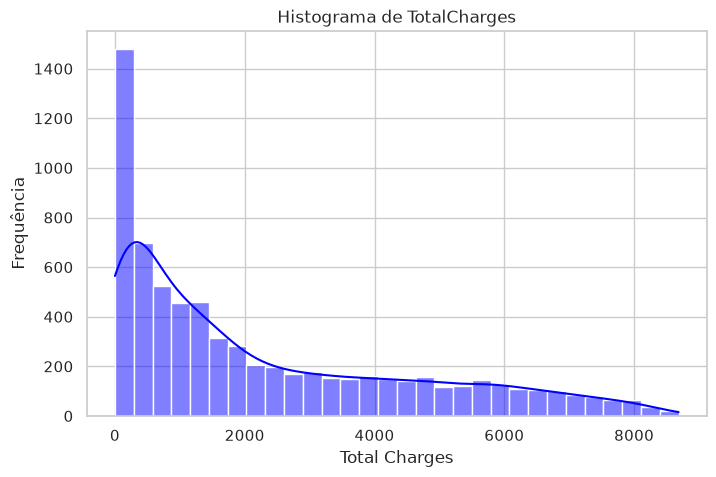

In [128]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='TotalCharges', bins=30, kde=True, color='blue')

plt.title('Histograma de TotalCharges')
plt.xlabel('Total Charges')
plt.ylabel('Frequência')

plt.show()

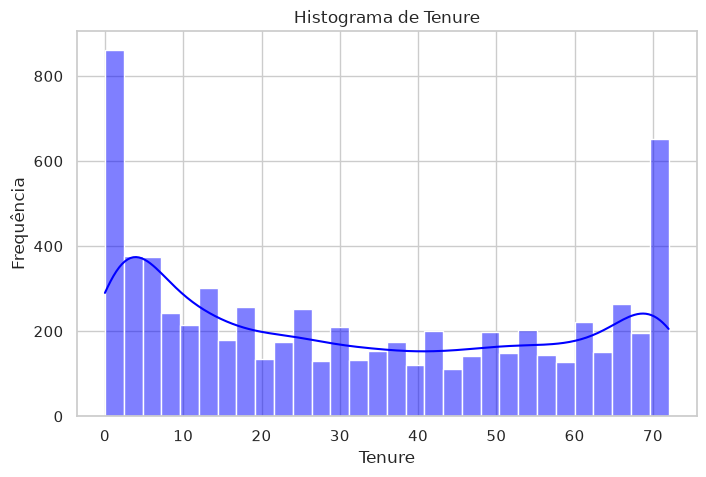

In [129]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='tenure', bins=30, kde=True, color='blue')

plt.title('Histograma de Tenure')
plt.xlabel('Tenure')
plt.ylabel('Frequência')

plt.show()

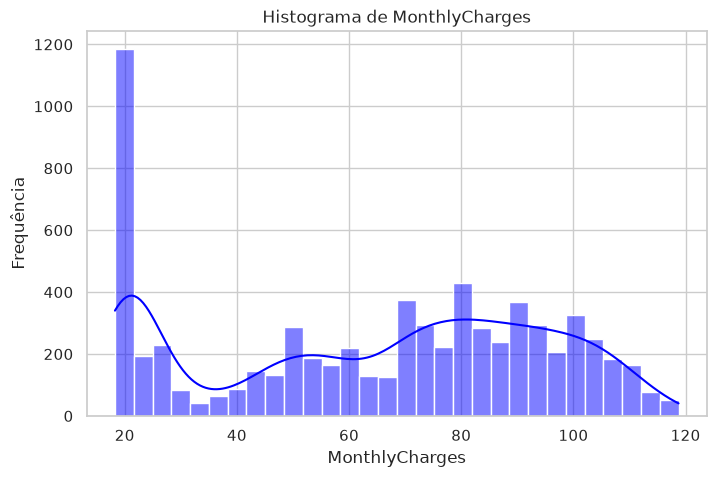

In [130]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True, color='blue')

plt.title('Histograma de MonthlyCharges')
plt.xlabel('MonthlyCharges')
plt.ylabel('Frequência')

plt.show()

In [131]:
colunas = ['tenure', 'MonthlyCharges', 'TotalCharges']
assimetrias = df[colunas].skew()

assimetrias

tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.963235
dtype: float64

**3.2** Aplique a transformação `np.log1p` à coluna `TotalCharges`. Compare o histograma e a assimetria antes e depois da transformação. A transformação logarítmica é adequada para esta coluna? Justifique com base nos valores obtidos.

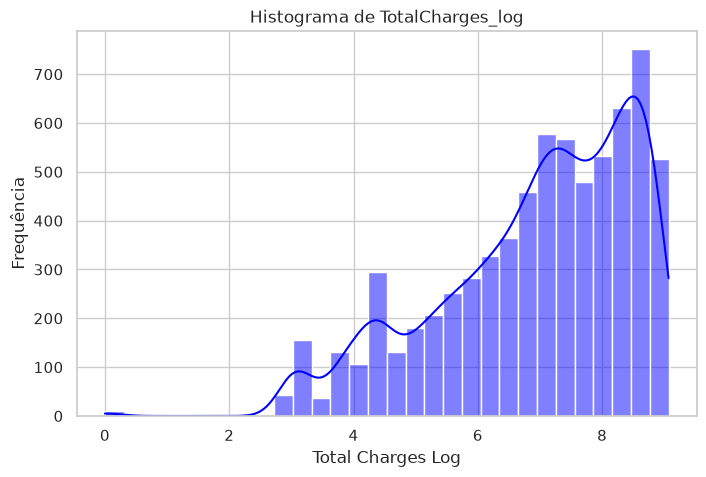

In [132]:
df['TotalCharges_log'] = np.log1p(df['TotalCharges'])
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='TotalCharges_log', bins=30, kde=True, color='blue')

plt.title('Histograma de TotalCharges_log')
plt.xlabel('Total Charges Log')
plt.ylabel('Frequência')

plt.show()

**Resposta:**

---
## Parte 4 — Codificação das variáveis categóricas

**4.1** Classifique as variáveis abaixo e indique a técnica de codificação adequada, preenchendo a tabela.

| Variável | Tipo (nominal, ordinal ou binária) | Técnica de codificação |
|---|---|---|
| gender | binaria|CND |
| Partner | binaria|CND |
| PhoneService | binaria|CND |
| MultipleLines | binaria|CND|
| InternetService | nominal|Agrupamento |
| OnlineSecurity | binaria|CND |
| Contract | nominal|Agrupamento |
| PaymentMethod | nominal|Agrupamento|
| Churn | binaria|CND |

**4.2** Converta para 0 e 1 as variáveis binárias `gender`, `Partner`, `Dependents`, `PhoneService`, `PaperlessBilling` e `Churn`.

In [133]:
df['gender']=df['gender'].map({'Male':False,'Female':True})
df['Partner']=df['Partner'].map({'Yes': True, 'No': False})
df['Dependents']=df['Dependents'].map({'Yes': True, 'No': False})
df['PhoneService']=df['PhoneService'].map({'Yes': True, 'No': False})
df['PaperlessBilling']=df['PaperlessBilling'].map({'Yes': True, 'No': False})
df['Churn']=df['Churn'].map({'Yes': True, 'No': False})

**4.3** As colunas de serviços adicionais (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) e a coluna `MultipleLines` possuem três valores. Analise o significado de "No internet service" e "No phone service", decida como codificar essas colunas e implemente a decisão.

In [134]:
df['OnlineSecurity']=df['OnlineSecurity'].map({'No internet service':0,'No':1,'Yes':2})
df['OnlineBackup']=df['OnlineBackup'].map({'No internet service':0,'No':1,'Yes':2})
df['DeviceProtection']=df['DeviceProtection'].map({'No internet service':0,'No':1,'Yes':2})
df['TechSupport']=df['TechSupport'].map({'No internet service':0,'No':1,'Yes':2})
df['StreamingTv']=df['StreamingTV'].map({'No internet service':0,'No':1,'Yes':2})
df['StreamingMovies']=df['StreamingMovies'].map({'No internet service':0,'No':1,'Yes':2})
df['MultipleLines']=df['MultipleLines'].map({'No phone service':0,'No':1,'Yes':2})

**Resposta:**

**4.4** Codifique `Contract` de forma ordinal, respeitando a ordem de duração do contrato.

In [135]:
df['Contract']=df['Contract'].map({'Month-to-month':0,'One year':1,'Two year':2})

**4.5** Aplique one-hot encoding a `InternetService` e `PaymentMethod`. Utilize ou não o parâmetro `drop_first` e justifique a escolha.

In [136]:
df['InternetService'].unique()
df_encoded=pd.get_dummies(df,columns=['InternetService','PaymentMethod'])
df_encoded

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,...,indice_valor_cliente,TotalCharges_log,StreamingTv,InternetService_DSL,InternetService_Fiber optic,InternetService_No,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,True,0,True,False,1,False,0,1,2,...,0.003437,3.429137,1,True,False,False,False,False,True,False
1,5575-GNVDE,False,0,False,False,34,True,1,2,1,...,0.217564,7.544597,1,True,False,False,False,False,False,True
2,3668-QPYBK,False,0,False,False,2,True,1,2,2,...,0.012453,4.692723,1,True,False,False,False,False,False,True
3,7795-CFOCW,False,0,False,False,45,False,0,2,1,...,0.211951,7.518471,1,True,False,False,True,False,False,False
4,9237-HQITU,True,0,False,False,2,True,1,1,1,...,0.017462,5.028148,1,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,False,0,True,True,24,True,2,2,1,...,0.229194,7.596643,2,True,False,False,False,False,False,True
7039,2234-XADUH,True,0,True,True,72,True,2,1,2,...,0.847792,8.904345,2,False,True,False,False,True,False,False
7040,4801-JZAZL,True,0,True,True,11,False,0,2,1,...,0.039892,5.850621,1,True,False,False,False,False,True,False
7041,8361-LTMKD,False,1,True,False,4,True,2,1,1,...,0.035303,5.728800,1,False,True,False,False,False,False,True


**Resposta:**

---
## Parte 5 — Análise do cancelamento para a diretoria comercial

**5.1** Utilizando a coluna `Churn` codificada, calcule a taxa de cancelamento (proporção de clientes que cancelaram) por tipo de contrato, por forma de pagamento e por tipo de internet.

In [137]:
taxa_contrato=df.groupby('Contract')['Churn'].mean()*100
taxa_pagamento=df.groupby('PaymentMethod')['Churn'].mean()*100
taxa_internet=df.groupby('InternetService')['Churn'].mean()*100
print(taxa_contrato,taxa_pagamento,taxa_internet)

Contract
0    42.709677
1    11.269518
2     2.831858
Name: Churn, dtype: float64 PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: Churn, dtype: float64 InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: Churn, dtype: float64


**5.2** Calcule a correlação entre `Churn` e as demais variáveis codificadas e numéricas. Apresente as cinco variáveis com maior correlação em valor absoluto, indicando o sentido (positivo ou negativo) de cada uma.

In [138]:
df_numerico = df.select_dtypes(include=['number', 'bool'])

corr_churn = df_numerico.corr()['Churn'].sort_values(ascending=False)

print(corr_churn)
#Contract,Tenure,TotalCharges,MonthlyCharges,PaperlessBilling

Churn                    1.000000
MonthlyCharges_minmax    0.193356
MonthlyCharges_z         0.193356
MonthlyCharges           0.193356
PaperlessBilling         0.191825
StreamingTv              0.164673
StreamingMovies          0.163220
SeniorCitizen            0.150889
DeviceProtection         0.084654
OnlineBackup             0.074205
MultipleLines            0.036310
TechSupport              0.027037
OnlineSecurity           0.023309
PhoneService             0.011942
gender                   0.008612
indice_padronizado      -0.140640
Partner                 -0.150448
indice_minmax           -0.150542
Dependents              -0.164221
indice_bruto            -0.196118
TotalCharges            -0.198324
indice_valor_cliente    -0.198324
TotalCharges_minmax     -0.198324
TotalCharges_z          -0.198324
TotalCharges_log        -0.233966
tenure_z                -0.352229
tenure                  -0.352229
tenure_minmax           -0.352229
Contract                -0.396713
Name: Churn, d

**5.3** Redija um parágrafo de até oito linhas dirigido à diretoria comercial, com uma recomendação para reduzir o cancelamento. A recomendação deve estar apoiada nos números obtidos em 5.1 e 5.2.

**Resposta:** Incentivar as pessoas a assinar contratos por mais tempo, pois a quantiade de tempo de contrato é inversamente proporcional ao churn, pois a taxa de correlação entre os dois é de -0.4, também comprovado pela taxa de tenure ser -0.35, portanto clientes que pagam por mais tempo tendem a não cancelar.

---
## Parte 6 — Questões discursivas

**6.1** Explique por que a codificação por rótulo (atribuir os números 0, 1, 2 e 3 às categorias de `PaymentMethod`) seria inadequada para a análise realizada na Parte 5.

**Resposta:** Pois um método de pagamento não é necessariamente maior ou melhor que o outro. Todas as opções são igualmente válidas, apenas importando se estão pagando.

**6.2** Descreva uma análise sobre esta base em que o escalonamento das métricas numéricas não alteraria o resultado. Justifique.

**Resposta:** Uma árvore de decisão, pois apenas é baseado em perguntas de sim ou não (Ex: Se o cliente possui 2 anos de tenure). Não importa o escalonamento, já que não é medida a distância entre os números.

**6.3** O coeficiente de correlação entre `tenure` e `Churn` muda se `tenure` for padronizada por z-score ou escalonada por min-max? Justifique matematicamente e, em seguida, verifique no código.

**Resposta:** Não, como visto acima, a correlação entre tenure por z-score, tenure por minmax e tenure pura e Churn é exatamente a mesma.